In [50]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
weekly_sales = pd.read_parquet(
    "../data/processed/weekly_sales.parquet"
)

weekly_sales.head()

,sku_id,date,quantity,promo_count,year,month,quarter,weekofyear,lag_1,lag_2,lag_4,rolling_mean_4,rolling_mean_8,has_promo,lag_8,rolling_std_4,expanding_mean,seasonal_naive
0,SKU00001,2023-02-19,9,0,2023,2,1,7,13.0,19.0,13.0,14.50,15.500,0,23.0,4.434712,19.433962,29.0
1,SKU00001,2023-02-26,15,0,2023,2,1,8,9.0,13.0,17.0,14.00,15.250,0,17.0,4.163332,19.351852,5.0
2,SKU00001,2023-03-05,25,0,2023,3,1,9,15.0,9.0,19.0,15.50,17.000,0,11.0,6.806859,19.454545,32.0
3,SKU00001,2023-03-12,27,12,2023,3,1,10,25.0,15.0,13.0,19.00,17.250,1,25.0,8.485281,19.589286,12.0
4,SKU00001,2023-03-19,26,12,2023,3,1,11,27.0,25.0,9.0,23.25,18.875,1,13.0,5.560276,19.701754,11.0


In [54]:
weekly_sales["seasonal_naive"] = (

    weekly_sales

    .groupby("sku_id")["quantity"]

    .shift(52)

)

In [56]:
weekly_sales = weekly_sales.dropna()

weekly_sales.shape

(478143, 18)

In [58]:
train_size = int(len(weekly_sales) * 0.8)

train = weekly_sales.iloc[:train_size]

test = weekly_sales.iloc[train_size:]

print(train.shape)

print(test.shape)

(382514, 18)
(95629, 18)


In [60]:
features = [

    "promo_count",

    "has_promo",

    "year",

    "month",

    "quarter",

    "weekofyear",

    "lag_1",

    "lag_2",

    "lag_4",

    "lag_8",

    "rolling_mean_4",

    "rolling_mean_8",

    "rolling_std_4",

    "expanding_mean"

]

In [62]:
target = "quantity"

In [64]:
X_train = train[features]

y_train = train[target]

X_test = test[features]

y_test = test[target]

In [66]:
baseline_pred = test["seasonal_naive"]

In [68]:
def wape(y_true, y_pred):

    return (

        np.abs(y_true - y_pred).sum()

        /

        np.abs(y_true).sum()

    ) * 100

In [70]:
baseline_mae = mean_absolute_error(

    y_test,

    baseline_pred

)

baseline_wape = wape(

    y_test,

    baseline_pred

)

print(

    "Baseline MAE:",

    baseline_mae

)

print(

    "Baseline WAPE:",

    baseline_wape

)

Baseline MAE: 7.3560321659747565
Baseline WAPE: 28.171749756207937


In [72]:
model = RandomForestRegressor(

    n_estimators=100,

    random_state=42,

    n_jobs=-1

)

model.fit(

    X_train,

    y_train

)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [74]:
predictions = model.predict(

    X_test

)

In [76]:
mae = mean_absolute_error(

    y_test,

    predictions

)

rmse = np.sqrt(

    mean_squared_error(

        y_test,

        predictions

    )

)

r2 = r2_score(

    y_test,

    predictions

)

model_wape = wape(

    y_test,

    predictions

)

print(

    "MAE:", mae

)

print(

    "RMSE:", rmse

)

print(

    "R2 Score:", r2

)

print(

    "Model WAPE:", model_wape

)

MAE: 8.925106400778008
RMSE: 162.92163044950956
R2 Score: 0.3428774385714365
Model WAPE: 34.18090872865693


In [78]:
comparison = pd.DataFrame(

    {

        "Metric": [

            "Baseline MAE",

            "Model MAE",

            "Baseline WAPE",

            "Model WAPE"

        ],

        "Value": [

            baseline_mae,

            mae,

            baseline_wape,

            model_wape

        ]

    }

)

comparison

,Metric,Value
0,Baseline MAE,7.356032
1,Model MAE,8.925106
2,Baseline WAPE,28.171750
3,Model WAPE,34.180909


In [80]:
importance = pd.DataFrame(

    {

        "Feature": features,

        "Importance": model.feature_importances_

    }

)

importance = importance.sort_values(

    by="Importance",

    ascending=False

)

importance

,Feature,Importance
10,rolling_mean_4,0.961821
12,rolling_std_4,0.008884
6,lag_1,0.006319
7,lag_2,0.005759
5,weekofyear,0.004829
13,expanding_mean,0.003145
11,rolling_mean_8,0.002176
8,lag_4,0.001871
9,lag_8,0.001766
0,promo_count,0.001556


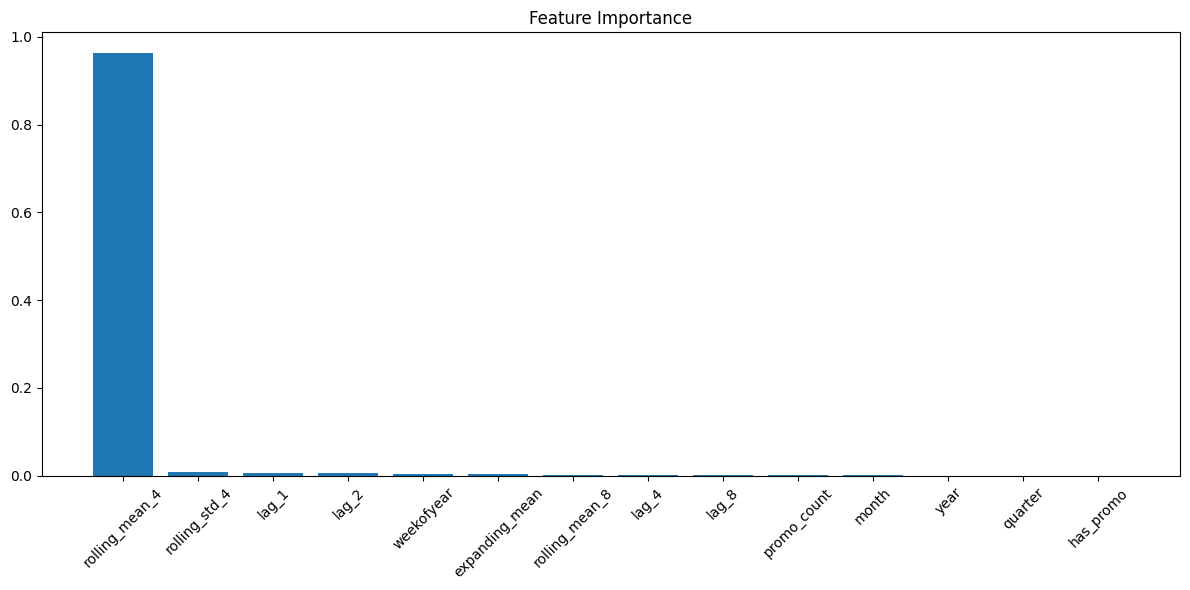

In [82]:
plt.figure(figsize=(12, 6))

plt.bar(

    importance["Feature"],

    importance["Importance"]

)

plt.xticks(rotation=45)

plt.title(

    "Feature Importance"

)

plt.tight_layout()

plt.savefig(

    "../reports/images/feature_importance.png",

    bbox_inches="tight"

)

plt.show()

In [84]:
import joblib

joblib.dump(

    model,

    "../models/forecast_model.pkl"

)

['../models/forecast_model.pkl']

In [90]:
results = test.copy()

results["predictions"] = predictions

results.to_parquet(

    "../data/processed/forecast_results.parquet",

    index=False

)

## Forecasting Conclusion

A Random Forest model was trained and evaluated against a seasonal-naive baseline.

Results showed that the Random Forest model achieved:

- MAE: 8.93
- WAPE: 34.18%

The seasonal-naive baseline achieved:

- MAE: 7.36
- WAPE: 28.17%

Since the baseline outperformed the Random Forest model, the seasonal-naive model was selected as the production forecasting approach for this project.